In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("skimage") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scikit-image"])

import csv
import hashlib
import json
import math
import platform
import random
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import skimage
import torch
import torch.nn as nn
import torchvision
from skimage.metrics import structural_similarity
from torch.utils.data import ConcatDataset, DataLoader, Subset
from torchvision import datasets, transforms

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"torchvision  : {torchvision.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"scikit-image : {skimage.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")
print(f"Device       : {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.13.16
PyTorch      : 2.14.1+cu130
torchvision  : 0.29.1+cu130
NumPy        : 2.4.6
scikit-image : 0.25.2
matplotlib   : 3.10.0
Device       : cuda
GPU          : Tesla T4


In [2]:
SEED = 42
MODEL_NAME = "01_vanilla_ae"
NUM_CLASSES = 10
IMAGE_SHAPE = (1, 28, 28)
INPUT_DIM = 28 * 28
HIDDEN_DIM = 256
LATENT_DIM = 64
BATCH_SIZE = 128
NUM_WORKERS = 2
PIN_MEMORY = torch.cuda.is_available()
LEARNING_RATE = 1e-3
NUM_EPOCHS = 30
TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 5600, 700, 700
SSIM_PARAMS = {
    "data_range": 1.0,
    "gaussian_weights": True,
    "sigma": 1.5,
    "win_size": 11,
    "use_sample_covariance": False,
}
LATENCY_BATCH_SIZE = 64
LATENCY_WARMUP_RUNS = 20
LATENCY_TIMED_RUNS = 100
INTERPOLATION_ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

try:
    from google.colab import drive
except ImportError as error:
    raise RuntimeError("This notebook is designed to run in Google Colab with Google Drive mounted.") from error
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/generative-model-comparison/01_vanilla_ae")
DATA_DIR = PROJECT_ROOT / "data" / "fashion_mnist"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in (DATA_DIR, RESULTS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = RESULTS_DIR / "best_model.pth"
METRICS_PATH = RESULTS_DIR / "metrics.json"
HISTORY_PATH = RESULTS_DIR / "training_history.csv"
CONFIG_PATH = RESULTS_DIR / "experiment_config.json"
SPLIT_REPORT_PATH = RESULTS_DIR / "split_report.json"
TRAINING_CURVES_PATH = FIGURES_DIR / "training_curves.png"
RECONSTRUCTION_PATH = FIGURES_DIR / "reconstruction_comparison.png"
INTERPOLATION_PATH = FIGURES_DIR / "latent_interpolation.png"

CONFIG = {
    "model_name": MODEL_NAME,
    "seed": SEED,
    "dataset": {
        "name": "Fashion-MNIST",
        "source": "torchvision.datasets.FashionMNIST, train=True (60,000) + train=False (10,000), pooled in that order",
        "total_images": 70000,
        "preprocessing": "transforms.ToTensor() only (grayscale [1, 28, 28], values in [0, 1])",
        "split": "class-stratified 80/10/10 with np.random.default_rng(42)",
        "split_per_class": {"train": TRAIN_PER_CLASS, "validation": VAL_PER_CLASS, "test": TEST_PER_CLASS},
    },
    "dataloader": {
        "batch_size": BATCH_SIZE,
        "train_shuffle": True,
        "train_generator_seed": SEED,
        "validation_shuffle": False,
        "test_shuffle": False,
        "num_workers": NUM_WORKERS,
        "pin_memory": PIN_MEMORY,
    },
    "model": {
        "type": "fully connected vanilla autoencoder",
        "encoder": "Flatten(784) -> Linear(784, 256) -> ReLU -> Linear(256, 64) -> ReLU",
        "decoder": "Linear(64, 256) -> ReLU -> Linear(256, 784) -> Sigmoid -> reshape [B, 1, 28, 28]",
        "input_dim": INPUT_DIM,
        "hidden_dim": HIDDEN_DIM,
        "latent_dim": LATENT_DIM,
    },
    "training": {
        "loss": 'nn.MSELoss(reduction="mean")',
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "betas": [0.9, 0.999],
        "eps": 1e-8,
        "weight_decay": 0.0,
        "epochs": NUM_EPOCHS,
        "early_stopping": False,
        "lr_scheduler": None,
        "gradient_clipping": None,
        "mixed_precision": False,
        "best_model_selection": "lowest validation MSE",
    },
    "evaluation": {
        "mse": "global sum of squared pixel errors / total test pixels",
        "psnr": "10 * log10(1.0 / MSE) in dB, computed from aggregate test MSE",
        "ssim": "mean of per-image skimage.metrics.structural_similarity over all test images",
        "ssim_params": SSIM_PARAMS,
        "latency": {"batch_size": LATENCY_BATCH_SIZE, "warmup_runs": LATENCY_WARMUP_RUNS, "timed_runs": LATENCY_TIMED_RUNS, "definition": "encoder + decoder forward pass",},
        "fid": "not computed (reconstruction-only experiment)",
    },
    "figures": {
        "reconstruction_classes": list(range(8)),
        "interpolation_classes": [0, 1],
        "interpolation_alphas": INTERPOLATION_ALPHAS,
    },
    "output_root": str(PROJECT_ROOT),
}

print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset cache: {DATA_DIR}")
print(f"Results      : {RESULTS_DIR}")

Mounted at /content/drive
Project root : /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae
Dataset cache: /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/data/fashion_mnist
Results      : /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results


In [3]:
transform = transforms.ToTensor()

fashion_train = datasets.FashionMNIST(root=str(DATA_DIR), train=True, download=True, transform=transform)
fashion_test = datasets.FashionMNIST(root=str(DATA_DIR), train=False, download=True, transform=transform)
assert len(fashion_train) == 60000, f"Expected 60,000 training images, got {len(fashion_train)}"
assert len(fashion_test) == 10000, f"Expected 10,000 test images, got {len(fashion_test)}"

full_dataset = ConcatDataset([fashion_train, fashion_test])
assert len(full_dataset) == 70000

CLASS_NAMES = list(fashion_train.classes)
assert len(CLASS_NAMES) == NUM_CLASSES
print("Classes:", CLASS_NAMES)

labels = np.concatenate([
    fashion_train.targets.numpy().astype(np.int64),
    fashion_test.targets.numpy().astype(np.int64),
])
assert labels.shape == (70000,)

rng = np.random.default_rng(SEED)

train_parts, val_parts, test_parts = [], [], []
for class_id in range(NUM_CLASSES):
    class_indices = np.flatnonzero(labels == class_id).copy()
    assert len(class_indices) == TRAIN_PER_CLASS + VAL_PER_CLASS + TEST_PER_CLASS, \
        f"Class {class_id} has {len(class_indices)} images, expected 7,000"
    rng.shuffle(class_indices)
    train_parts.append(class_indices[:5600])
    val_parts.append(class_indices[5600:6300])
    test_parts.append(class_indices[6300:])

train_indices = np.concatenate(train_parts).astype(np.int64)
val_indices = np.concatenate(val_parts).astype(np.int64)
test_indices = np.concatenate(test_parts).astype(np.int64)

rng.shuffle(train_indices)
rng.shuffle(val_indices)
rng.shuffle(test_indices)

assert len(train_indices) == 56000, len(train_indices)
assert len(val_indices) == 7000, len(val_indices)
assert len(test_indices) == 7000, len(test_indices)

per_class_counts = {}
for split_name, split_indices, expected in (
    ("train", train_indices, TRAIN_PER_CLASS),
    ("validation", val_indices, VAL_PER_CLASS),
    ("test", test_indices, TEST_PER_CLASS),
):
    counts = np.bincount(labels[split_indices], minlength=NUM_CLASSES)
    assert np.all(counts == expected), f"{split_name} per-class counts are wrong: {counts}"
    per_class_counts[split_name] = {CLASS_NAMES[c]: int(counts[c]) for c in range(NUM_CLASSES)}

train_set, val_set, test_set = set(train_indices.tolist()), set(val_indices.tolist()), set(test_indices.tolist())
assert len(train_set) == 56000 and len(val_set) == 7000 and len(test_set) == 7000, "Duplicate indices inside a split"
assert train_set.isdisjoint(val_set), "Train/validation overlap"
assert train_set.isdisjoint(test_set), "Train/test overlap"
assert val_set.isdisjoint(test_set), "Validation/test overlap"
all_indices = np.sort(np.concatenate([train_indices, val_indices, test_indices]))
assert np.array_equal(all_indices, np.arange(70000)), "Splits do not cover all 70,000 indices"


def sha256_of_indices(index_array):
    return hashlib.sha256(np.ascontiguousarray(index_array, dtype=np.int64).tobytes()).hexdigest()


split_hashes = {
    "train": sha256_of_indices(train_indices),
    "validation": sha256_of_indices(val_indices),
    "test": sha256_of_indices(test_indices),
}
split_counts = {"train": int(len(train_indices)), "validation": int(len(val_indices)), "test": int(len(test_indices))}

split_report = {
    "seed": SEED,
    "total_images": int(len(labels)),
    "pool_order": "torchvision FashionMNIST train=True (indices 0-59999) then train=False (indices 60000-69999)",
    "split_counts": split_counts,
    "per_class_counts": per_class_counts,
    "index_sha256_int64": split_hashes,
    "checks": {
        "exact_totals": True,
        "per_class_counts": True,
        "no_overlap": True,
        "full_coverage": True,
    },
}

print("All split assertions passed.")
print("Split counts:", split_counts)
for name, digest in split_hashes.items():
    print(f"SHA-256 {name:<10}: {digest}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 221kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.17MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 31.5MB/s]


Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
All split assertions passed.
Split counts: {'train': 56000, 'validation': 7000, 'test': 7000}
SHA-256 train     : 33ea53524b4322bff6a3800d5f997fb49a2c3109cc676bcec3f5bd75614d563f
SHA-256 validation: ec0ca9f1abc64ba260835d8b8ade0d19c59aed038153fbab1103386380698254
SHA-256 test      : e10a9ab4471795dfab37b6b9a652c9a27f56343cea3a08bb82b97de2332bc3a1


Train: 56,000 images, 438 batches
Val  : 7,000 images, 55 batches
Test : 7,000 images, 55 batches


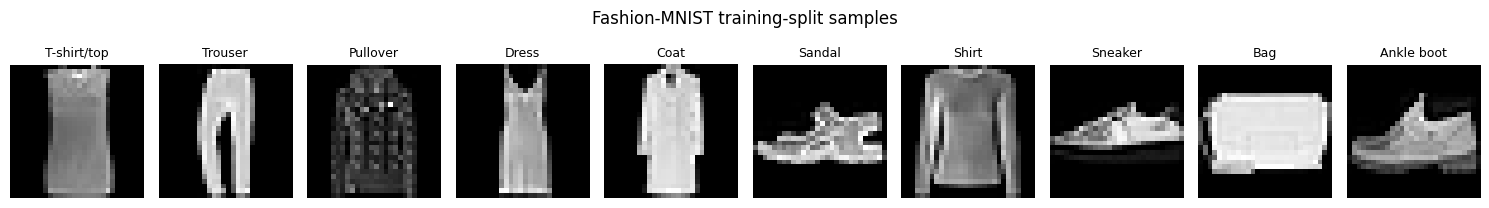

In [4]:
train_dataset = Subset(full_dataset, train_indices.tolist())
val_dataset = Subset(full_dataset, val_indices.tolist())
test_dataset = Subset(full_dataset, test_indices.tolist())

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

print(f"Train: {len(train_dataset):,} images, {len(train_loader)} batches")
print(f"Val  : {len(val_dataset):,} images, {len(val_loader)} batches")
print(f"Test : {len(test_dataset):,} images, {len(test_loader)} batches")

sample_image, sample_label = train_dataset[0]
assert tuple(sample_image.shape) == IMAGE_SHAPE, sample_image.shape
assert sample_image.dtype == torch.float32
assert 0.0 <= sample_image.min().item() and sample_image.max().item() <= 1.0

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 2.2))
for class_id in range(NUM_CLASSES):
    position = int(np.flatnonzero(labels[train_indices] == class_id)[0])
    image, label = train_dataset[position]
    assert label == class_id
    axes[class_id].imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0.0, vmax=1.0)
    axes[class_id].set_title(CLASS_NAMES[class_id], fontsize=9)
    axes[class_id].axis("off")
fig.suptitle("Fashion-MNIST training-split samples")
plt.tight_layout()
plt.show()

In [5]:
class VanillaAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(INPUT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, INPUT_DIM),
            nn.Sigmoid(),
        )

    def encode(self, images):
        return self.encoder(images)

    def decode(self, latent):
        return self.decoder(latent).view(-1, *IMAGE_SHAPE)

    def forward(self, images):
        latent = self.encode(images)
        reconstruction = self.decode(latent)
        return reconstruction, latent


seed_everything(SEED)
model = VanillaAutoencoder().to(DEVICE)
print(model)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert trainable_params == 435536, trainable_params
print(f"Trainable parameters: {trainable_params:,}")

check_images, _ = next(iter(val_loader))
check_images = check_images.to(DEVICE)
with torch.no_grad():
    check_recon, check_latent = model(check_images)
assert check_recon.shape == check_images.shape == (check_images.size(0), *IMAGE_SHAPE), check_recon.shape
assert check_latent.shape == (check_images.size(0), LATENT_DIM), check_latent.shape
assert check_recon.min().item() >= 0.0 and check_recon.max().item() <= 1.0, "Sigmoid output outside [0, 1]"
assert check_latent.min().item() >= 0.0, "ReLU latent should be non-negative"
linear_layers = [m for m in model.modules() if isinstance(m, nn.Linear)]
assert [(l.in_features, l.out_features) for l in linear_layers] == [(784, 256), (256, 64), (64, 256), (256, 784)]
assert not any(isinstance(m, (nn.Conv2d, nn.Dropout, nn.BatchNorm1d, nn.BatchNorm2d)) for m in model.modules())
print("Architecture and output-range assertions passed.")

VanillaAutoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Trainable parameters: 435,536
Architecture and output-range assertions passed.


In [6]:
criterion = nn.MSELoss(reduction="mean")
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


history = []
best_val_mse = float("inf")
best_epoch = None

synchronize_device()
training_start = time.perf_counter()
for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.perf_counter()

    model.train()
    synchronize_device()
    train_start = time.perf_counter()
    train_loss_sum, train_samples = 0.0, 0
    for images, _ in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        reconstruction, _ = model(images)
        loss = criterion(reconstruction, images)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * images.size(0)
        train_samples += images.size(0)
    synchronize_device()
    train_time_s = time.perf_counter() - train_start
    assert train_samples == len(train_dataset)
    train_mse = train_loss_sum / train_samples

    model.eval()
    synchronize_device()
    val_start = time.perf_counter()
    val_loss_sum, val_samples = 0.0, 0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            reconstruction, _ = model(images)
            val_loss_sum += criterion(reconstruction, images).item() * images.size(0)
            val_samples += images.size(0)
    synchronize_device()
    val_time_s = time.perf_counter() - val_start
    assert val_samples == len(val_dataset)
    val_mse = val_loss_sum / val_samples

    is_best = val_mse < best_val_mse
    if is_best:
        best_val_mse, best_epoch = val_mse, epoch
        torch.save({
            "model_name": MODEL_NAME,
            "model_class": "VanillaAutoencoder",
            "model_state_dict": model.state_dict(),
            "best_epoch": best_epoch,
            "best_val_mse": best_val_mse,
            "latent_dim": LATENT_DIM,
            "trainable_params": trainable_params,
            "config": CONFIG,
        }, BEST_MODEL_PATH)

    epoch_time_s = time.perf_counter() - epoch_start
    history.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "val_mse": val_mse,
        "train_time_s": train_time_s,
        "val_time_s": val_time_s,
        "epoch_time_s": epoch_time_s,
        "is_best": is_best,
    })
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | train MSE {train_mse:.6f} | val MSE {val_mse:.6f} | "
          f"train {train_time_s:.1f}s | val {val_time_s:.1f}s | epoch {epoch_time_s:.1f}s"
          + (" | best, saved" if is_best else ""))

synchronize_device()
total_training_time_s = time.perf_counter() - training_start
completed_epochs = len(history)
mean_epoch_train_time_s = float(np.mean([row["train_time_s"] for row in history]))

assert completed_epochs == NUM_EPOCHS
assert BEST_MODEL_PATH.exists(), "best_model.pth was not saved"
print(f"\nTraining finished: {completed_epochs} epochs in {total_training_time_s:.1f}s "
      f"(mean training time per epoch {mean_epoch_train_time_s:.1f}s)")
print(f"Best epoch: {best_epoch} with validation MSE {best_val_mse:.6f}")

Epoch 01/30 | train MSE 0.035358 | val MSE 0.019621 | train 9.0s | val 0.8s | epoch 9.8s | best, saved
Epoch 02/30 | train MSE 0.017770 | val MSE 0.016727 | train 7.8s | val 0.8s | epoch 8.7s | best, saved
Epoch 03/30 | train MSE 0.015129 | val MSE 0.014193 | train 6.4s | val 0.8s | epoch 7.3s | best, saved
Epoch 04/30 | train MSE 0.013671 | val MSE 0.013082 | train 8.0s | val 0.8s | epoch 8.8s | best, saved
Epoch 05/30 | train MSE 0.012709 | val MSE 0.012230 | train 6.3s | val 1.0s | epoch 7.4s | best, saved
Epoch 06/30 | train MSE 0.012020 | val MSE 0.011539 | train 7.9s | val 0.8s | epoch 8.7s | best, saved
Epoch 07/30 | train MSE 0.011412 | val MSE 0.011188 | train 7.1s | val 1.2s | epoch 8.2s | best, saved
Epoch 08/30 | train MSE 0.010929 | val MSE 0.010678 | train 7.0s | val 0.8s | epoch 7.9s | best, saved
Epoch 09/30 | train MSE 0.010561 | val MSE 0.010318 | train 7.8s | val 1.0s | epoch 8.8s | best, saved
Epoch 10/30 | train MSE 0.010208 | val MSE 0.009991 | train 6.4s | val 0.

Loaded best checkpoint from epoch 30 (validation MSE 0.007928)


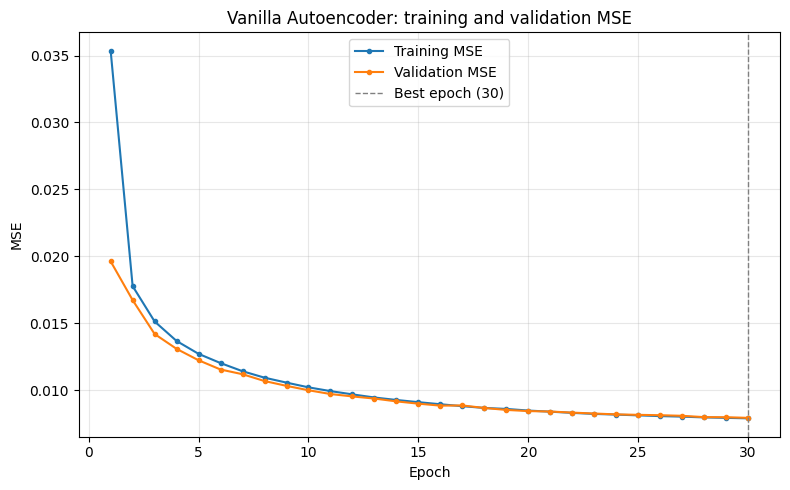

Saved /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/figures/training_curves.png


In [7]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=True)
assert checkpoint["best_epoch"] == best_epoch
assert math.isclose(checkpoint["best_val_mse"], best_val_mse)

best_model = VanillaAutoencoder().to(DEVICE)
best_model.load_state_dict(checkpoint["model_state_dict"])
best_model.eval()
print(f"Loaded best checkpoint from epoch {checkpoint['best_epoch']} "
      f"(validation MSE {checkpoint['best_val_mse']:.6f})")

epochs = [row["epoch"] for row in history]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(epochs, [row["train_mse"] for row in history], marker="o", markersize=3, label="Training MSE")
ax.plot(epochs, [row["val_mse"] for row in history], marker="o", markersize=3, label="Validation MSE")
ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"Best epoch ({best_epoch})")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
ax.set_title("Vanilla Autoencoder: training and validation MSE")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(TRAINING_CURVES_PATH, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {TRAINING_CURVES_PATH}")

In [8]:
squared_error_sum = 0.0
total_pixels = 0
ssim_values = []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        reconstruction, _ = best_model(images)
        squared_error_sum += (reconstruction.double() - images.double()).pow(2).sum().item()
        total_pixels += images.numel()

        originals_np = images.squeeze(1).cpu().numpy()
        reconstructions_np = reconstruction.squeeze(1).cpu().numpy()
        for original, recon in zip(originals_np, reconstructions_np):
            ssim_values.append(float(structural_similarity(original, recon, **SSIM_PARAMS)))

assert total_pixels == len(test_dataset) * INPUT_DIM, total_pixels
assert len(ssim_values) == len(test_dataset) == 7000, len(ssim_values)

test_mse = squared_error_sum / total_pixels
test_psnr = float("inf") if test_mse == 0 else 10.0 * math.log10(1.0 / test_mse)
test_ssim_mean = float(np.mean(ssim_values))

print(f"Test images   : {len(ssim_values):,}")
print(f"Test MSE      : {test_mse:.6f}")
print(f"Test PSNR     : {test_psnr:.4f} dB")
print(f"Test mean SSIM: {test_ssim_mean:.6f}")

Test images   : 7,000
Test MSE      : 0.008073
Test PSNR     : 20.9297 dB
Test mean SSIM: 0.745186


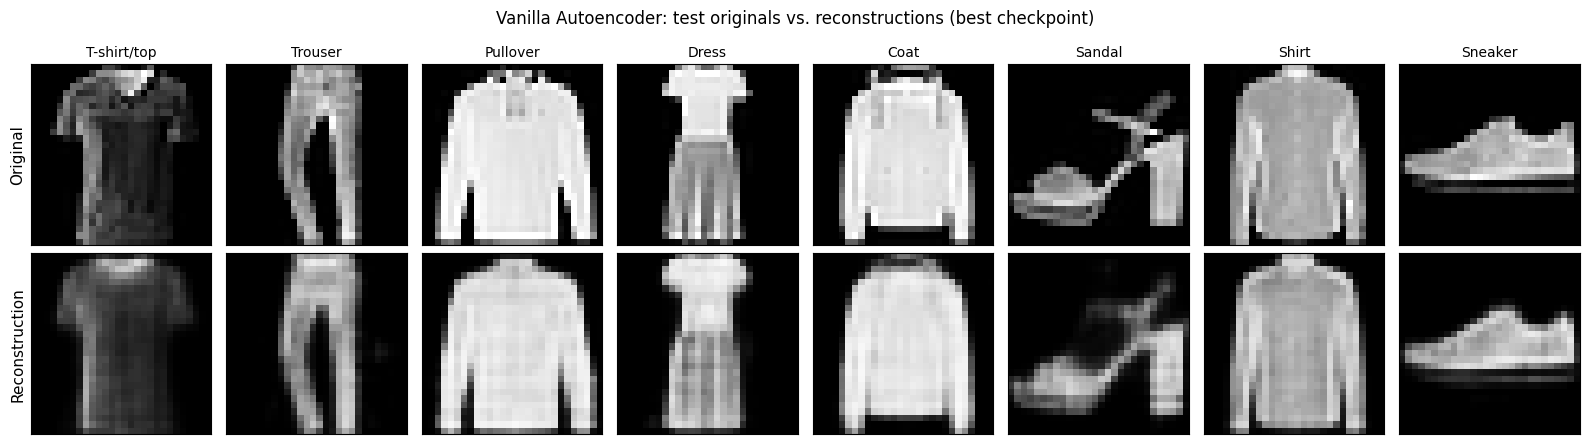

Saved /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/figures/reconstruction_comparison.png


In [9]:
test_labels = labels[test_indices]


def first_test_position(class_id):
    return int(np.flatnonzero(test_labels == class_id)[0])


reconstruction_classes = list(range(8))
selected_positions = [first_test_position(c) for c in reconstruction_classes]
selected_images = torch.stack([test_dataset[p][0] for p in selected_positions]).to(DEVICE)
for position, class_id in zip(selected_positions, reconstruction_classes):
    assert test_dataset[position][1] == class_id

with torch.no_grad():
    selected_recons, _ = best_model(selected_images)

fig, axes = plt.subplots(2, len(reconstruction_classes), figsize=(2 * len(reconstruction_classes), 4.6))
for column, class_id in enumerate(reconstruction_classes):
    for row, batch in enumerate((selected_images, selected_recons)):
        ax = axes[row, column]
        ax.imshow(batch[column, 0].cpu().numpy(), cmap="gray", vmin=0.0, vmax=1.0)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[0, column].set_title(CLASS_NAMES[class_id], fontsize=10)
axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("Reconstruction", fontsize=11)
fig.suptitle("Vanilla Autoencoder: test originals vs. reconstructions (best checkpoint)")
plt.tight_layout()
fig.savefig(RECONSTRUCTION_PATH, dpi=150, bbox_inches="tight")
plt.show()

reconstruction_samples = [
    {"class_id": c, "class_name": CLASS_NAMES[c], "test_split_position": p, "pooled_index": int(test_indices[p])}
    for c, p in zip(reconstruction_classes, selected_positions)
]
print(f"Saved {RECONSTRUCTION_PATH}")

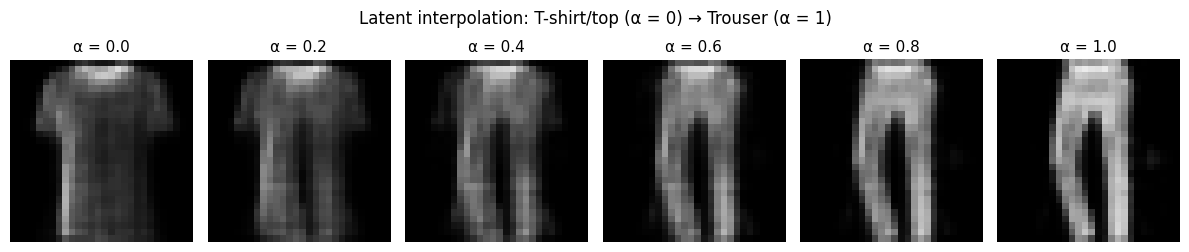

Saved /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/figures/latent_interpolation.png


In [10]:
start_position, end_position = first_test_position(0), first_test_position(1)
start_image = test_dataset[start_position][0].unsqueeze(0).to(DEVICE)
end_image = test_dataset[end_position][0].unsqueeze(0).to(DEVICE)

with torch.no_grad():
    z_start = best_model.encode(start_image)
    z_end = best_model.encode(end_image)
    assert z_start.shape == z_end.shape == (1, LATENT_DIM)
    interpolated_latents = torch.cat([(1.0 - alpha) * z_start + alpha * z_end for alpha in INTERPOLATION_ALPHAS])
    interpolated_images = best_model.decode(interpolated_latents)
assert interpolated_images.shape == (len(INTERPOLATION_ALPHAS), *IMAGE_SHAPE)

fig, axes = plt.subplots(1, len(INTERPOLATION_ALPHAS), figsize=(2 * len(INTERPOLATION_ALPHAS), 2.6))
for ax, alpha, image in zip(axes, INTERPOLATION_ALPHAS, interpolated_images):
    ax.imshow(image[0].cpu().numpy(), cmap="gray", vmin=0.0, vmax=1.0)
    ax.set_title(f"α = {alpha:.1f}", fontsize=11)
    ax.axis("off")
fig.suptitle(f"Latent interpolation: {CLASS_NAMES[0]} (α = 0) → {CLASS_NAMES[1]} (α = 1)")
plt.tight_layout()
fig.savefig(INTERPOLATION_PATH, dpi=150, bbox_inches="tight")
plt.show()

interpolation_endpoints = {
    "start": {"class_id": 0, "class_name": CLASS_NAMES[0], "test_split_position": start_position,
              "pooled_index": int(test_indices[start_position])},
    "end": {"class_id": 1, "class_name": CLASS_NAMES[1], "test_split_position": end_position,
            "pooled_index": int(test_indices[end_position])},
}
print(f"Saved {INTERPOLATION_PATH}")

In [11]:
best_model.eval()
latency_input = torch.stack([
    test_dataset[i][0] for i in range(LATENCY_BATCH_SIZE)
]).to(DEVICE)
assert latency_input.shape == (LATENCY_BATCH_SIZE, *IMAGE_SHAPE)

latency_runs_ms = []
with torch.inference_mode():
    for _ in range(LATENCY_WARMUP_RUNS):
        _ = best_model(latency_input)
    synchronize_device()

    for _ in range(LATENCY_TIMED_RUNS):
        synchronize_device()
        t0 = time.perf_counter()
        _ = best_model(latency_input)
        synchronize_device()
        latency_runs_ms.append((time.perf_counter() - t0) * 1000.0)

latency_runs_ms = np.asarray(latency_runs_ms, dtype=np.float64)
latency_ms_per_batch = float(latency_runs_ms.mean())
latency_ms_per_image = latency_ms_per_batch / LATENCY_BATCH_SIZE
hardware_name = (
    torch.cuda.get_device_name(0)
    if DEVICE.type == "cuda"
    else (platform.processor() or platform.machine())
)

print(f"Device: {DEVICE} ({hardware_name})")
print(f"Latency: {latency_ms_per_batch:.4f} ms/batch of {LATENCY_BATCH_SIZE}")
print(f"Per-image equivalent: {latency_ms_per_image:.4f} ms/image")
print(f"Runs: {LATENCY_WARMUP_RUNS} warm-up, {LATENCY_TIMED_RUNS} timed")

Device: cuda (Tesla T4)
Latency: 0.2437 ms/batch of 64
Per-image equivalent: 0.0038 ms/image
Runs: 20 warm-up, 100 timed


In [12]:
runtime_versions = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "scikit_image": skimage.__version__,
    "matplotlib": matplotlib.__version__,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
    "platform": platform.platform(),
}

artifact_paths = {
    "best_model": str(BEST_MODEL_PATH),
    "metrics": str(METRICS_PATH),
    "training_history": str(HISTORY_PATH),
    "experiment_config": str(CONFIG_PATH),
    "split_report": str(SPLIT_REPORT_PATH),
    "training_curves": str(TRAINING_CURVES_PATH),
    "reconstruction_comparison": str(RECONSTRUCTION_PATH),
    "latent_interpolation": str(INTERPOLATION_PATH),
}

metrics = {
    "model_name": MODEL_NAME,
    "seed": SEED,
    "split_counts": split_counts,
    "split_index_sha256_int64": split_hashes,
    "best_epoch": best_epoch,
    "best_val_mse": best_val_mse,
    "test": {
        "num_images": len(ssim_values),
        "mse": test_mse,
        "psnr_db": test_psnr if math.isfinite(test_psnr) else "inf",
        "ssim_mean": test_ssim_mean,
        "ssim_params": SSIM_PARAMS,
        "ssim_aggregation": "arithmetic mean of per-image SSIM over all test images",
    },
    "completed_epochs": completed_epochs,
    "total_training_time_s": total_training_time_s,
    "mean_epoch_train_time_s": mean_epoch_train_time_s,
    "trainable_params": trainable_params,
    "latent_dim": LATENT_DIM,
    "inference_latency": {
        "mean_ms_per_batch": latency_ms_per_batch,
        "ms_per_image": latency_ms_per_image,
        "batch_size": LATENCY_BATCH_SIZE,
        "warmup_runs": LATENCY_WARMUP_RUNS,
        "timed_runs": LATENCY_TIMED_RUNS,
        "device": str(DEVICE),
        "hardware": hardware_name,
        "definition": "encoder + decoder forward pass",
        "note": "Hardware-dependent; compare latency across models only on the same hardware.",
    },
    "fid": "not computed (reconstruction-only experiment)",
    "figure_samples": {
        "reconstruction": reconstruction_samples,
        "interpolation_endpoints": interpolation_endpoints,
        "interpolation_alphas": INTERPOLATION_ALPHAS,
    },
    "runtime_versions": runtime_versions,
    "artifact_paths": artifact_paths,
}

with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2, allow_nan=False)
with open(CONFIG_PATH, "w") as f:
    json.dump({**CONFIG, "runtime_versions": runtime_versions}, f, indent=2)
with open(SPLIT_REPORT_PATH, "w") as f:
    json.dump(split_report, f, indent=2)
with open(HISTORY_PATH, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
    writer.writeheader()
    writer.writerows(history)

print("Saved artifacts:")
for name, path in artifact_paths.items():
    print(f"  {name:<26} {path}")
print("\nCommit to GitHub: notebook, JSON/CSV files and figures.")
print("Keep in Google Drive only (do NOT commit): data/fashion_mnist/ and results/best_model.pth")

Saved artifacts:
  best_model                 /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/best_model.pth
  metrics                    /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/metrics.json
  training_history           /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/training_history.csv
  experiment_config          /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/experiment_config.json
  split_report               /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/split_report.json
  training_curves            /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/figures/training_curves.png
  reconstruction_comparison  /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/figures/reconstruction_comparison.png
  latent_interpolation       /content/drive/MyDrive/generative-model-comparison/01_vanilla_ae/results/figures/lat

In [13]:
checks = []


def check(description, condition):
    checks.append((description, bool(condition)))


for name, path in artifact_paths.items():
    check(f"{name} exists and is non-empty", Path(path).exists() and Path(path).stat().st_size > 0)

with open(METRICS_PATH) as f:
    saved_metrics = json.load(f)
with open(SPLIT_REPORT_PATH) as f:
    saved_split = json.load(f)
with open(HISTORY_PATH) as f:
    saved_history = list(csv.DictReader(f))
saved_checkpoint = torch.load(BEST_MODEL_PATH, map_location="cpu", weights_only=True)

check("Split counts are 56,000 / 7,000 / 7,000",
      saved_split["split_counts"] == {"train": 56000, "validation": 7000, "test": 7000})
check("Every class has 5,600 / 700 / 700 samples",
      all(set(saved_split["per_class_counts"][s].values()) == {n}
          for s, n in (("train", 5600), ("validation", 700), ("test", 700))))
check("Split hashes in metrics.json match split_report.json",
      saved_metrics["split_index_sha256_int64"] == saved_split["index_sha256_int64"])
check("Exactly 30 epochs completed", saved_metrics["completed_epochs"] == 30 and len(saved_history) == 30)
check("Best epoch is the epoch with the lowest validation MSE",
      saved_metrics["best_epoch"] == min(history, key=lambda r: r["val_mse"])["epoch"])
check("Checkpoint stores state dict, best epoch, best val MSE and config",
      all(k in saved_checkpoint for k in ("model_state_dict", "best_epoch", "best_val_mse", "config", "model_name")))
check("Checkpoint best epoch matches metrics.json", saved_checkpoint["best_epoch"] == saved_metrics["best_epoch"])
check("Trainable parameter count is 435,536", saved_metrics["trainable_params"] == 435536)
check("SSIM computed on all 7,000 test images", saved_metrics["test"]["num_images"] == 7000)
check("SSIM parameters match the protocol", saved_metrics["test"]["ssim_params"] == SSIM_PARAMS)
check("PSNR is consistent with test MSE",
      saved_metrics["test"]["psnr_db"] == "inf"
      or math.isclose(saved_metrics["test"]["psnr_db"], 10 * math.log10(1 / saved_metrics["test"]["mse"])))
lat = saved_metrics["inference_latency"]
check(
    "Inference latency uses batch 64, 20 warm-ups and 100 timed runs",
    lat["batch_size"] == 64
    and lat["warmup_runs"] == 20
    and lat["timed_runs"] == 100
    and math.isfinite(lat["mean_ms_per_batch"])
    and math.isfinite(lat["ms_per_image"]),
)

for description, passed in checks:
    print(f"[{'PASS' if passed else 'FAIL'}] {description}")
assert all(passed for _, passed in checks), "One or more verification checks failed."
print(f"\nAll {len(checks)} checks passed. Outputs are in {RESULTS_DIR}")

[PASS] best_model exists and is non-empty
[PASS] metrics exists and is non-empty
[PASS] training_history exists and is non-empty
[PASS] experiment_config exists and is non-empty
[PASS] split_report exists and is non-empty
[PASS] training_curves exists and is non-empty
[PASS] reconstruction_comparison exists and is non-empty
[PASS] latent_interpolation exists and is non-empty
[PASS] Split counts are 56,000 / 7,000 / 7,000
[PASS] Every class has 5,600 / 700 / 700 samples
[PASS] Split hashes in metrics.json match split_report.json
[PASS] Exactly 30 epochs completed
[PASS] Best epoch is the epoch with the lowest validation MSE
[PASS] Checkpoint stores state dict, best epoch, best val MSE and config
[PASS] Checkpoint best epoch matches metrics.json
[PASS] Trainable parameter count is 435,536
[PASS] SSIM computed on all 7,000 test images
[PASS] SSIM parameters match the protocol
[PASS] PSNR is consistent with test MSE
[PASS] Inference latency uses batch 64, 20 warm-ups and 100 timed runs

Al